In [15]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [16]:
pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


find r2 score without feature selection and time


In [17]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rajyellow46/wine-quality")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\dell\.cache\kagglehub\datasets\rajyellow46\wine-quality\versions\1


In [18]:
import os
path=os.path.join(path, "winequalityN.csv")
df=pd.read_csv(path)

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [ ]:
X_train, y_train, X_test, y_test = train_test_split(df.drop('quality', axis=1), df['quality'], test_size=0.2, random_state=42)

In [21]:
df["type"]=df["type"].map({"red":0, "white":1})

In [22]:
df.describe()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6487.000000,6489.000000,6494.000000,6495.000000,6495.000000,6497.000000,6497.000000,6497.000000,6488.000000,6493.000000,6497.000000,6497.000000
mean,0.753886,7.216579,0.339691,0.318722,5.444326,0.056042,30.525319,115.744574,0.994697,3.218395,0.531215,10.491801,5.818378
std,0.430779,1.296750,0.164649,0.145265,4.758125,0.035036,17.749400,56.521855,0.002999,0.160748,0.148814,1.192712,0.873255
min,0.000000,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,1.000000,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,1.000000,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,1.000000,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,1.000000,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [ ]:
# Feature Selection
#1.no dublicate columns
#2.no constant columns

In [37]:
df.shape

(6497, 13)

In [ ]:
columns_to_drop = df.drop(['type','quality'], axis=1).columns
result=[]
for i, col in enumerate(columns_to_drop):
    result.append([col, df[col].quantile(0.95)])
result

[['fixed acidity', np.float64(9.8)],
 ['volatile acidity', np.float64(0.67)],
 ['citric acid', np.float64(0.56)],
 ['residual sugar', np.float64(15.0)],
 ['chlorides', np.float64(0.102)],
 ['free sulfur dioxide', np.float64(61.0)],
 ['total sulfur dioxide', np.float64(206.0)],
 ['density', np.float64(0.999392)],
 ['pH', np.float64(3.5)],
 ['sulphates', np.float64(0.79)],
 ['alcohol', np.float64(12.7)]]

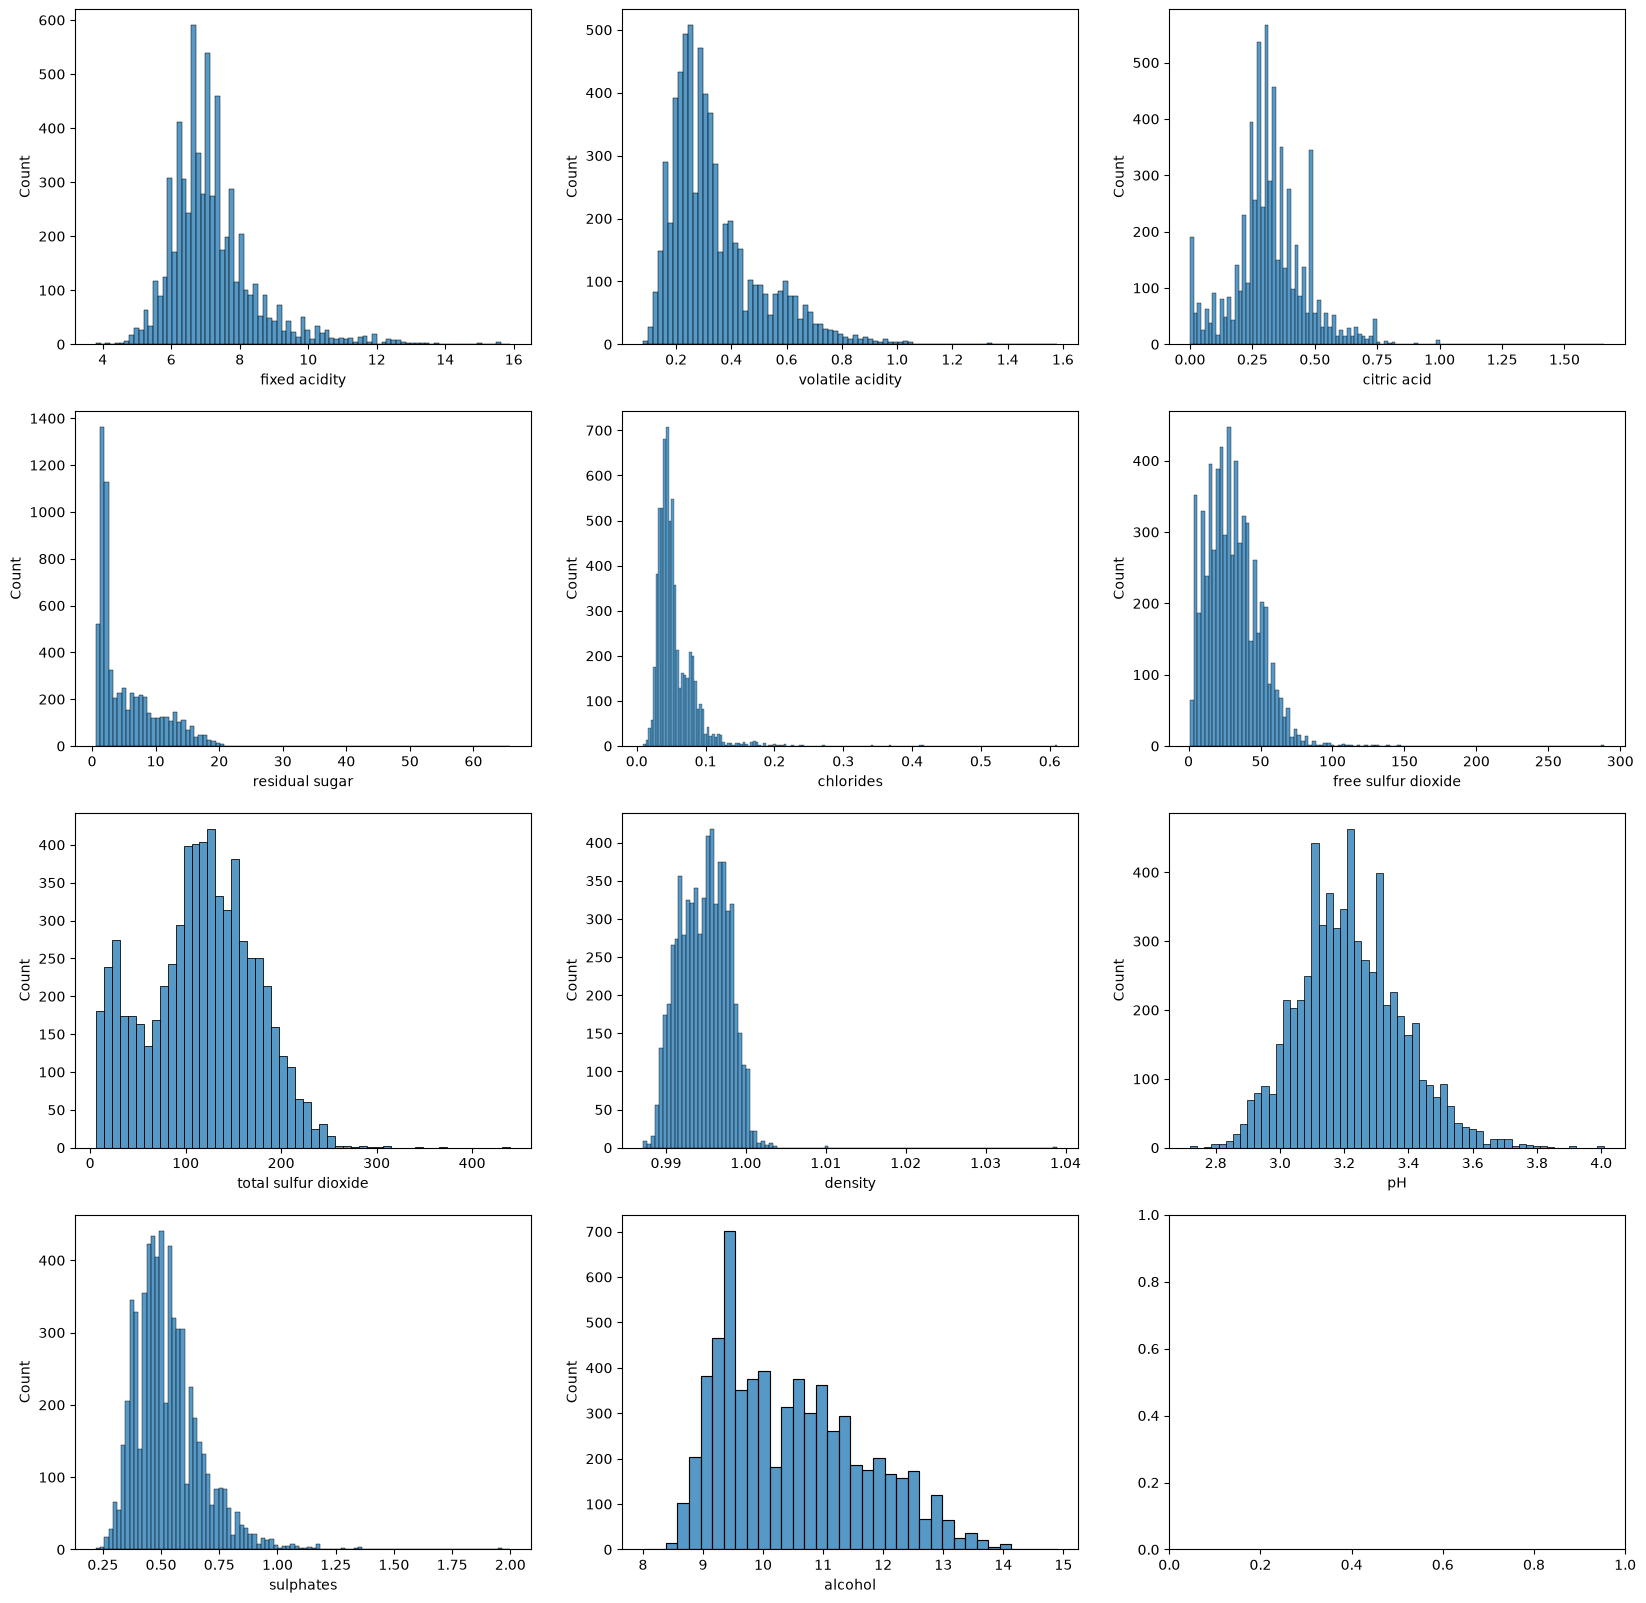

In [36]:
columns_to_drop = df.drop(['type','quality'], axis=1).columns
f,axis=plt.subplots(4, 3, figsize=(20,20))
for i, col in enumerate(columns_to_drop):
    sns.histplot(data=df, x=col, ax=axis[i//3, i%3])